# Feature Reduction

### <i> Using PCA

`PCA` is a method for combining features and compresses your columns into principal components while preserving as much variation as possible.

Imagine you have a dataset with 50 features -- With PCA, say most of the variation in the dataset can be captured by 5 principal components effectively...

That saves computation time and also may improve your model accuracy! 

</i>



<strong> [Video about PCA inner workings](https://www.youtube.com/watch?v=FgakZw6K1QQ&t=12s) </strong>


<br>
<br>

<i>

### Problems with PCA 

* The new columns you create with PCA will not be interpratable anymore.

* This is only for linear-like datasets (HEAVY non-linearity). Expect performance to suffer if it isn't linear (See KPCA.)

* Going back from PCA --> Original meaningful data has a cost, reconstruction error.



<br>
<br>

### Danger:

Remember to split the data before using `StandardScaler()`, or you'll introduce a dataleak.

</i>

<br>
<br>

---


### Problem



<i> I've loaded in the scikit-learn breast_cancer dataset. 

The current problem is that the the dataset below has 31 columns and they're all reasonably useful for the target.

You're in a conundrum. You need less features to make the ML model function better, but you still want all the useful features. What's the solution?


<strong style='color:orange ; background-color:black;'>PCA is a good solution because we can condense all the features while retaining more variance </strong>


In [8]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

# Load dataset
data = load_breast_cancer(as_frame=True)

# Turn the data into a pandas dataframe.
df = data.data.copy()
df["target"] = data.target

df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


<i>

Let's get to it.

---

### 2 principal components

<i> Let's first show you a basic example of PCA.

<i> We're going to start simple and split our dataset into only 2 principal components. The point is so that you can see bad results and good results.

This will be the bad results example.



In [9]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Separate features and target
X = df.drop(columns="target")
y = df["target"]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reduce 30 features to 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Store results in a DataFrame
pca_df = pd.DataFrame(
    X_pca,
    index=df.index
)

pca_df["target"] = y

variance = pca.explained_variance_ratio_

# Some useful metrics which allow you to see how much
# variance was lost in your dataset. 

# The more variance lost, the less real the dataset becomes
# and performance may suffer. It's a balance between 
# keeping features in to preserve variance while simplifying
# features to its principal components.

print(f"PC1 variance: {variance[0]:.2%}")
print(f"PC2 variance: {variance[1]:.2%}")
print(f"Total variance retained: {variance.sum():.2%}")

pca_df

# Notice how variance retained is abysmally low. It depends on your use case but 
# I typically go for >80-90%. 

PC1 variance: 44.27%
PC2 variance: 18.97%
Total variance retained: 63.24%


,0,1,target
0,9.192837,1.948583,0
1,2.387802,-3.768172,0
2,5.733896,-1.075174,0
3,7.122953,10.275589,0
4,3.935302,-1.948072,0
...,...,...,...
564,6.439315,-3.576817,0
565,3.793382,-3.584048,0
566,1.256179,-1.902297,0
567,10.374794,1.672010,0


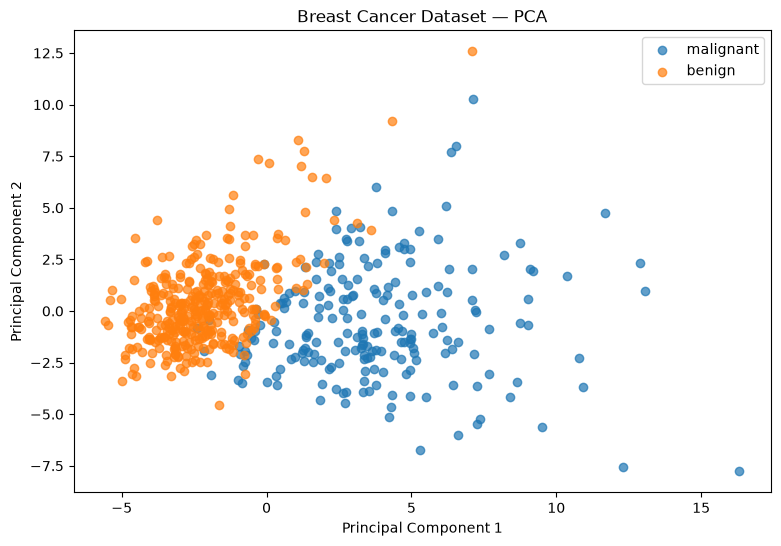

In [10]:
# Now, let's check out how much overlap and spread+direction exists
# From our PCA transformation.
plt.figure(figsize=(9, 6))

for label, name in enumerate(data.target_names):
    subset = pca_df[pca_df["target"] == label]

    # Keep in mind that if you have more principal components, 
    # You'll have to add those additional subsets in the plot below.
    plt.scatter(
        subset[0],
        subset[1],
        label=name,
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Breast Cancer Dataset — PCA")
plt.legend()
plt.show()

# See below for how to read it.


<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h3> <strong style='color:Orange'>What to look for:</strong></h3>



- Overlap: Do the classes `malignant` and `benign` have overlap?
- Structure: does the data show a dominant spread in direction? If yes, then you may want to try more `n_components`

<br>
<br>

#### <strong style='color:Orange'>Overlap</strong> 

Clear overlap in the middle and it's pretty bad. This means that two components alone don't separate the classes well enough within that overlap and if you can't do that visually, the ML model can't either.

<br>

#### <strong style='color:Orange'>Spread & direction</strong>

`PC1` clearly has a bigger spread than `PC2`.

That's normal, since `PC1` tries to cover the most variation as possible in one feature dimension and then `PC2` captures that remaining variance as much as possible in that feature dimension.

<br>
<br>

Note:

Had they both looked nearly identical in spread... that suggests that the variance may already have been capped out... And you may not get very much more out of `PCA`. :(

</div>




---

### 5 principal components

<i> Now, we've shown an example that didn't work too well -- Let's show you some more components to see if it works better.

We're going to raise the number of `n_components` to 5. Please note the variance retained below.

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Separate features and target
X = df.drop(columns="target")
y = df["target"]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reduce 30 features to 5 components
pca = PCA(n_components=5)
X_pca = pca.fit_transform(X_scaled)

# Store results in a DataFrame
pca_df = pd.DataFrame(
    X_pca,
    index=df.index
)

pca_df["target"] = y

variance = pca.explained_variance_ratio_

# Some useful metrics which allow you to see how much
# variance was lost in your dataset. 

# The more variance lost, the less real the dataset becomes
# and performance may suffer. It's a balance between 
# keeping features in to preserve variance while simplifying
# features to its principal components.

print(f"PC1 variance: {variance[0]:.2%}")
print(f"PC2 variance: {variance[1]:.2%}")
print(f"Total variance retained: {variance.sum():.2%}")

pca_df

PC1 variance: 44.27%
PC2 variance: 18.97%
Total variance retained: 84.73%


,0,1,2,3,4,target
0,9.192837,1.948583,-1.123166,-3.633731,1.195110,0
1,2.387802,-3.768172,-0.529293,-1.118264,-0.621775,0
2,5.733896,-1.075174,-0.551748,-0.912083,0.177086,0
3,7.122953,10.275589,-3.232790,-0.152547,2.960878,0
4,3.935302,-1.948072,1.389767,-2.940639,-0.546747,0
...,...,...,...,...,...,...
564,6.439315,-3.576817,2.459487,-1.177314,0.074824,0
565,3.793382,-3.584048,2.088476,2.506028,0.510723,0
566,1.256179,-1.902297,0.562731,2.089227,-1.809991,0
567,10.374794,1.672010,-1.877029,2.356031,0.033742,0


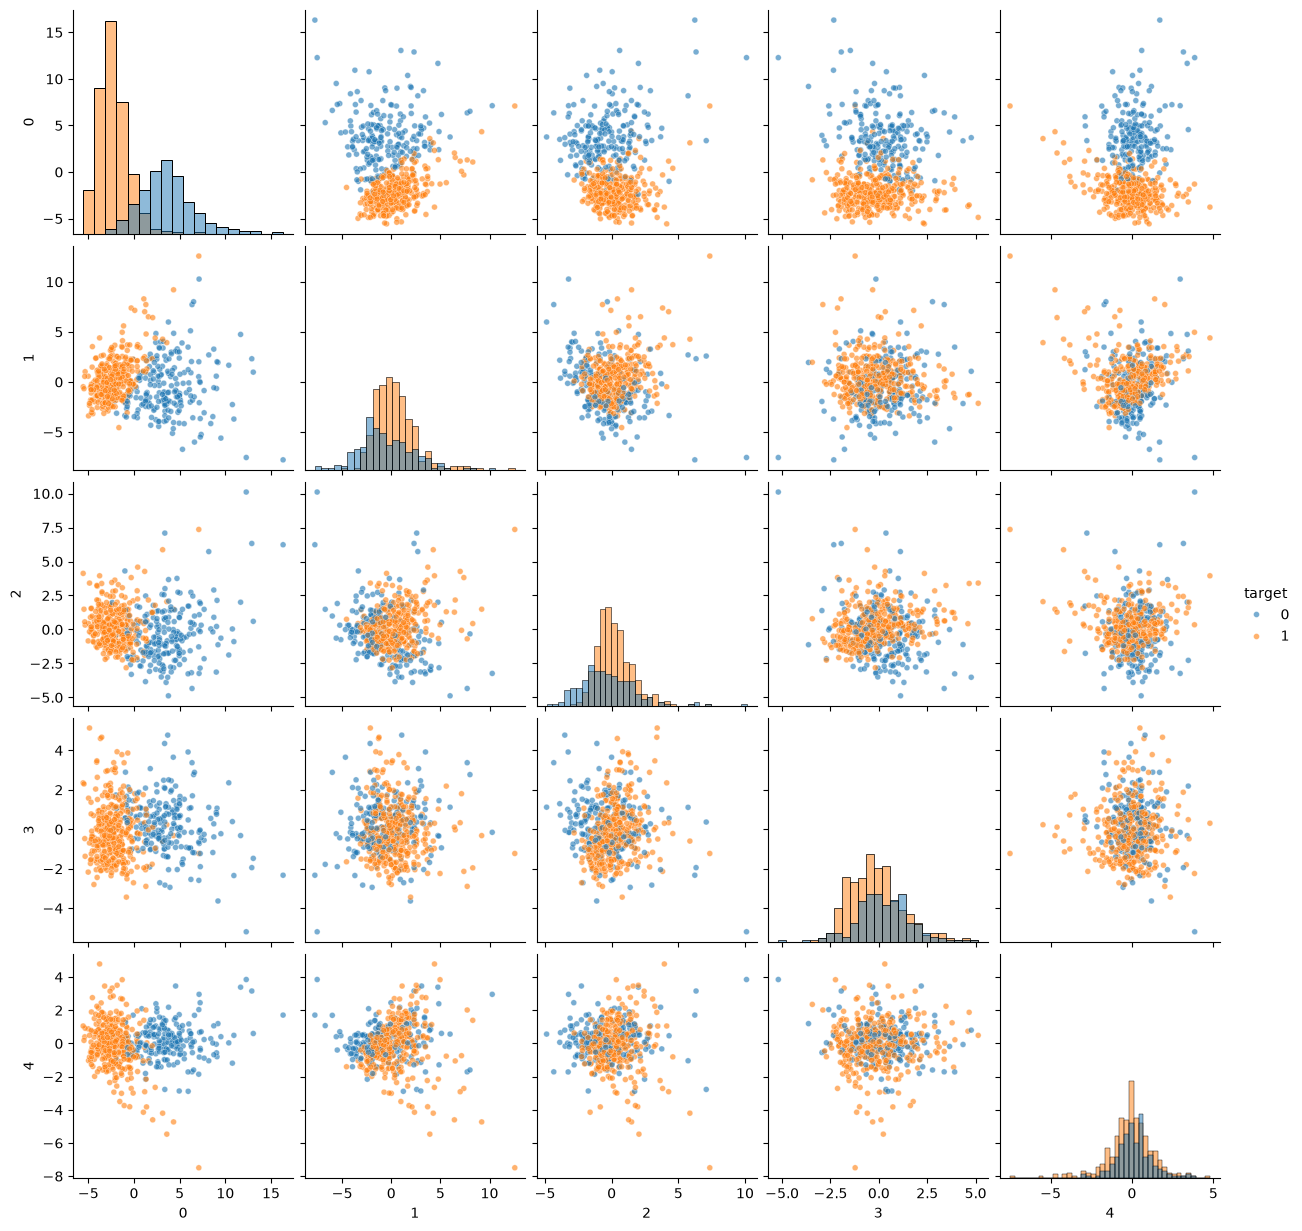

In [12]:
# Now we have multiple dimensions, we can't fit it into a single visual anymore.
# So, we're going to use a pairplot.

# NOTE: If the visual is overwhelming, that's totally normal. For one, this is
# meant to be an exploratory tool. The idea is that you keep trying 
# Different `n_components` until you get something with the least 
# overlap.

# Interpreting these gets easier over time!
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(
    pca_df,
    vars=[0, 1, 2, 3, 4], # INSERT THE PCA COMPONENT columns HERE!
    hue="target",
    diag_kind="hist",
    plot_kws={"alpha": 0.6, "s": 18}
)

plt.show()

---

## Reconstruction

<i> One of the largest problems about `PCA` is that you don't know what the columns really mean anymore, they're ambiguous. 

You can reconstruct the original dataset. But it comes with a price.

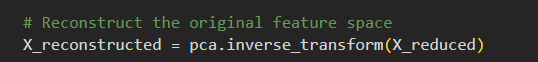


</i>

#####  <strong style='color:red'>Reconstruction error!</strong>


In [13]:

import numpy as np
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

# Fit PCA using the standardized feature matrix
pca = PCA(n_components=8)
X_reduced = pca.fit_transform(X_scaled)

# Reconstruct the original feature space
X_reconstructed = pca.inverse_transform(X_reduced)

reconstructed_df = pd.DataFrame(
    X_reconstructed,
    columns=X.columns,
    index=X.index
)

reconstructed_df["target"] = y
reconstructed_df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,1.433004,-1.440384,1.575441,1.602864,2.213250,2.787584,2.239509,2.311058,2.688413,2.101637,...,-1.332878,1.880544,1.859296,1.417477,2.336092,1.874834,2.059763,2.444934,2.293143,0
1,1.475309,-0.235916,1.423734,1.457027,-0.434125,0.044584,0.444684,0.772989,-0.528052,-1.231129,...,-0.314795,1.371592,1.401046,-0.350651,0.082633,0.320692,0.742158,-0.221114,-0.612734,0
2,1.634718,0.069738,1.656887,1.583549,0.795849,1.233482,1.477281,1.672085,0.958376,-0.239972,...,0.080372,1.617702,1.509044,0.658133,1.015818,1.263890,1.631215,1.016836,0.211978,0
3,-1.049880,0.027615,-0.795167,-0.958415,2.988777,3.315561,1.937700,1.187766,4.695125,4.307727,...,0.491980,-0.173621,-0.424419,3.420110,3.796165,2.703081,1.752731,5.667867,4.571213,0
4,1.536035,-1.074238,1.519618,1.595239,0.621743,0.534730,1.072713,1.334677,-0.349524,-0.616741,...,-1.395573,1.307260,1.374760,0.367115,-0.119552,0.422467,0.980116,-0.859489,-0.737848,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,2.300712,0.398955,2.286367,2.416343,0.985246,0.872377,1.560370,2.040145,-0.570666,-0.778070,...,0.104853,2.114009,2.252374,0.548343,-0.058025,0.561987,1.404683,-1.589859,-0.841083,0
565,1.620209,2.133077,1.589143,1.586126,-0.063762,0.272817,0.838658,1.209630,-0.017013,-1.201082,...,2.069089,1.438453,1.432650,-0.613426,-0.249984,0.199956,0.756564,-0.757117,-1.130656,0
566,0.708281,1.510246,0.676288,0.663220,-1.146036,-0.125461,0.328891,0.168290,-1.156740,-0.864839,...,1.385101,0.640816,0.616893,-0.648640,0.245336,0.520618,0.337399,-0.820162,-0.170153,0
567,1.782284,2.225251,1.907705,1.703993,1.510047,2.841568,2.719465,2.523258,1.925809,1.257859,...,2.544911,2.175406,1.907074,1.780902,3.108860,3.012233,2.848342,2.330538,2.467377,0


#### Comparing the reconstructed dataset with the PCA version

<i>

Now lets compare the reconstructed dataset with the original and see how much it holds up!

We're mainly interested two things

* The mean absolute correlation error (How much different are the correlations between the original and the reconstructed dataset?)

* The reconstruction MSE. (On average, how off is each value when reconstructing the dataframe?)

In [14]:
# Correlation matrices
corr_original = np.corrcoef(X_scaled, rowvar=False)
corr_reconstructed = np.corrcoef(
    X_reconstructed, rowvar=False
)

# Compare only off-diagonal correlations
mask = ~np.eye(corr_original.shape[0], dtype=bool)

mean_corr_error = np.mean(
    np.abs(
        corr_original[mask] - corr_reconstructed[mask]
    )
)

# Reconstruction error
mse = mean_squared_error(X_scaled, X_reconstructed)

print(f"Variance retained: {pca.explained_variance_ratio_.sum():.2%}")

# From a scale of 0 - 1, how much did the reconstructed df change from the original's pairwise-correlations?
# If the correlations have been largely lost, reconstruction is probably not viable, since it
# destroyed the original relationships. 
print(f"Mean absolute correlation error: {mean_corr_error:.4f}")

# These tell you how much average error was produced during the reconstruction.
print(f"Reconstruction MSE: {mse:.6f}")


Variance retained: 92.60%
Mean absolute correlation error: 0.0379
Reconstruction MSE: 0.074017




<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h3>Observations</h3>

* After reconstructing this dataframe <strong style='color:orange ; background-color:black;'> an average of +- .07 of error was introducted for each value. </strong>  

* The <strong style='color:orange ; background-color:black;'> correlations between each column have, on average, shifted by around 3% </strong> . That's quite a penalty, but depending on your use case -- That might be OK!



</div>